In [ ]:
#!pip install --upgrade nvidia-cudnn-cu12==9.23.2.1
#!pip install --no-deps fvcore

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=21281ccc9b1ddaa1ec9c6590888fe7a52976ef7d54c52e0adffb5061fd5332c2
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
Successfully built fvcore


In [2]:
!pip install --no-deps -q fvcore iopath termcolor pyyaml portalocker

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.4 MB/s eta 0:00:00


In [3]:
import torch
import torchvision
import torch.nn.functional as F
from torchvision.models import VGG16_Weights

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f" torch: {torch.__version__}")
print(f" torchvision: {torchvision.__version__}")
print(f" cuDNN: {torch.backends.cudnn.version()}")
print(f" CUDA: {torch.cuda.is_available()}")

x = torch.randn(1, 3, 32, 32, device='cuda')
w = torch.randn(16, 3, 3, 3, device='cuda')
y = F.conv2d(x, w, padding=1)
print(f"Convolucion OK, salida: {y.shape}")
print(f"VGG16_Weights: {VGG16_Weights.IMAGENET1K_V1}")

GPU: Tesla T4
 torch: 2.11.0+cu130
 torchvision: 0.26.0+cu130
 cuDNN: 92700
 CUDA: True
Convolucion OK, salida: torch.Size([1, 16, 32, 32])
VGG16_Weights: VGG16_Weights.IMAGENET1K_V1


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
from torchvision.models import VGG16_Weights

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split
from collections import Counter
import time
import copy
import os
import json

from fvcore.nn import FlopCountAnalysis

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [5]:
train_raw = datasets.CIFAR10(root="./data", train=True, download=True)
test_raw  = datasets.CIFAR10(root="./data", train=False, download=True)

100%|██████████| 170M/170M [33:44<00:00, 84.2kB/s]


In [6]:
classes = train_raw.classes
print(f"Clases ({len(classes)}): {classes}")
print(f"Observaciones train: {len(train_raw)}")
print(f"Observaciones test:  {len(test_raw)}")

#balance clases
train_labels = [label for _, label in train_raw]
class_counts = Counter(train_labels)
print("\nDistribución de clases (train):")
for i, cls in enumerate(classes):
    pct = class_counts[i] / len(train_labels) * 100
    print(f"  {cls:12s}: {class_counts[i]:5d} ({pct}%)")

#resolucion y canales
img, _ = train_raw[0]
print(f"\nResolución: {img.size}, Canales: {len(np.array(img).shape)}")

#media y std/canal
train_data = train_raw.data.astype(np.float32) / 255.0
mean = train_data.mean(axis=(0, 1, 2))
std  = train_data.std(axis=(0, 1, 2))
print(f"\nMedia por canal CIFAR-10: {mean}")
print(f"Std por canal CIFAR-10:   {std}")

Clases (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Observaciones train: 50000
Observaciones test:  10000

Distribución de clases (train):
  airplane    :  5000 (10.0%)
  automobile  :  5000 (10.0%)
  bird        :  5000 (10.0%)
  cat         :  5000 (10.0%)
  deer        :  5000 (10.0%)
  dog         :  5000 (10.0%)
  frog        :  5000 (10.0%)
  horse       :  5000 (10.0%)
  ship        :  5000 (10.0%)
  truck       :  5000 (10.0%)

Resolución: (32, 32), Canales: 3

Media por canal CIFAR-10: [0.4914009  0.48215896 0.4465308 ]
Std por canal CIFAR-10:   [0.24703279 0.24348423 0.26158753]


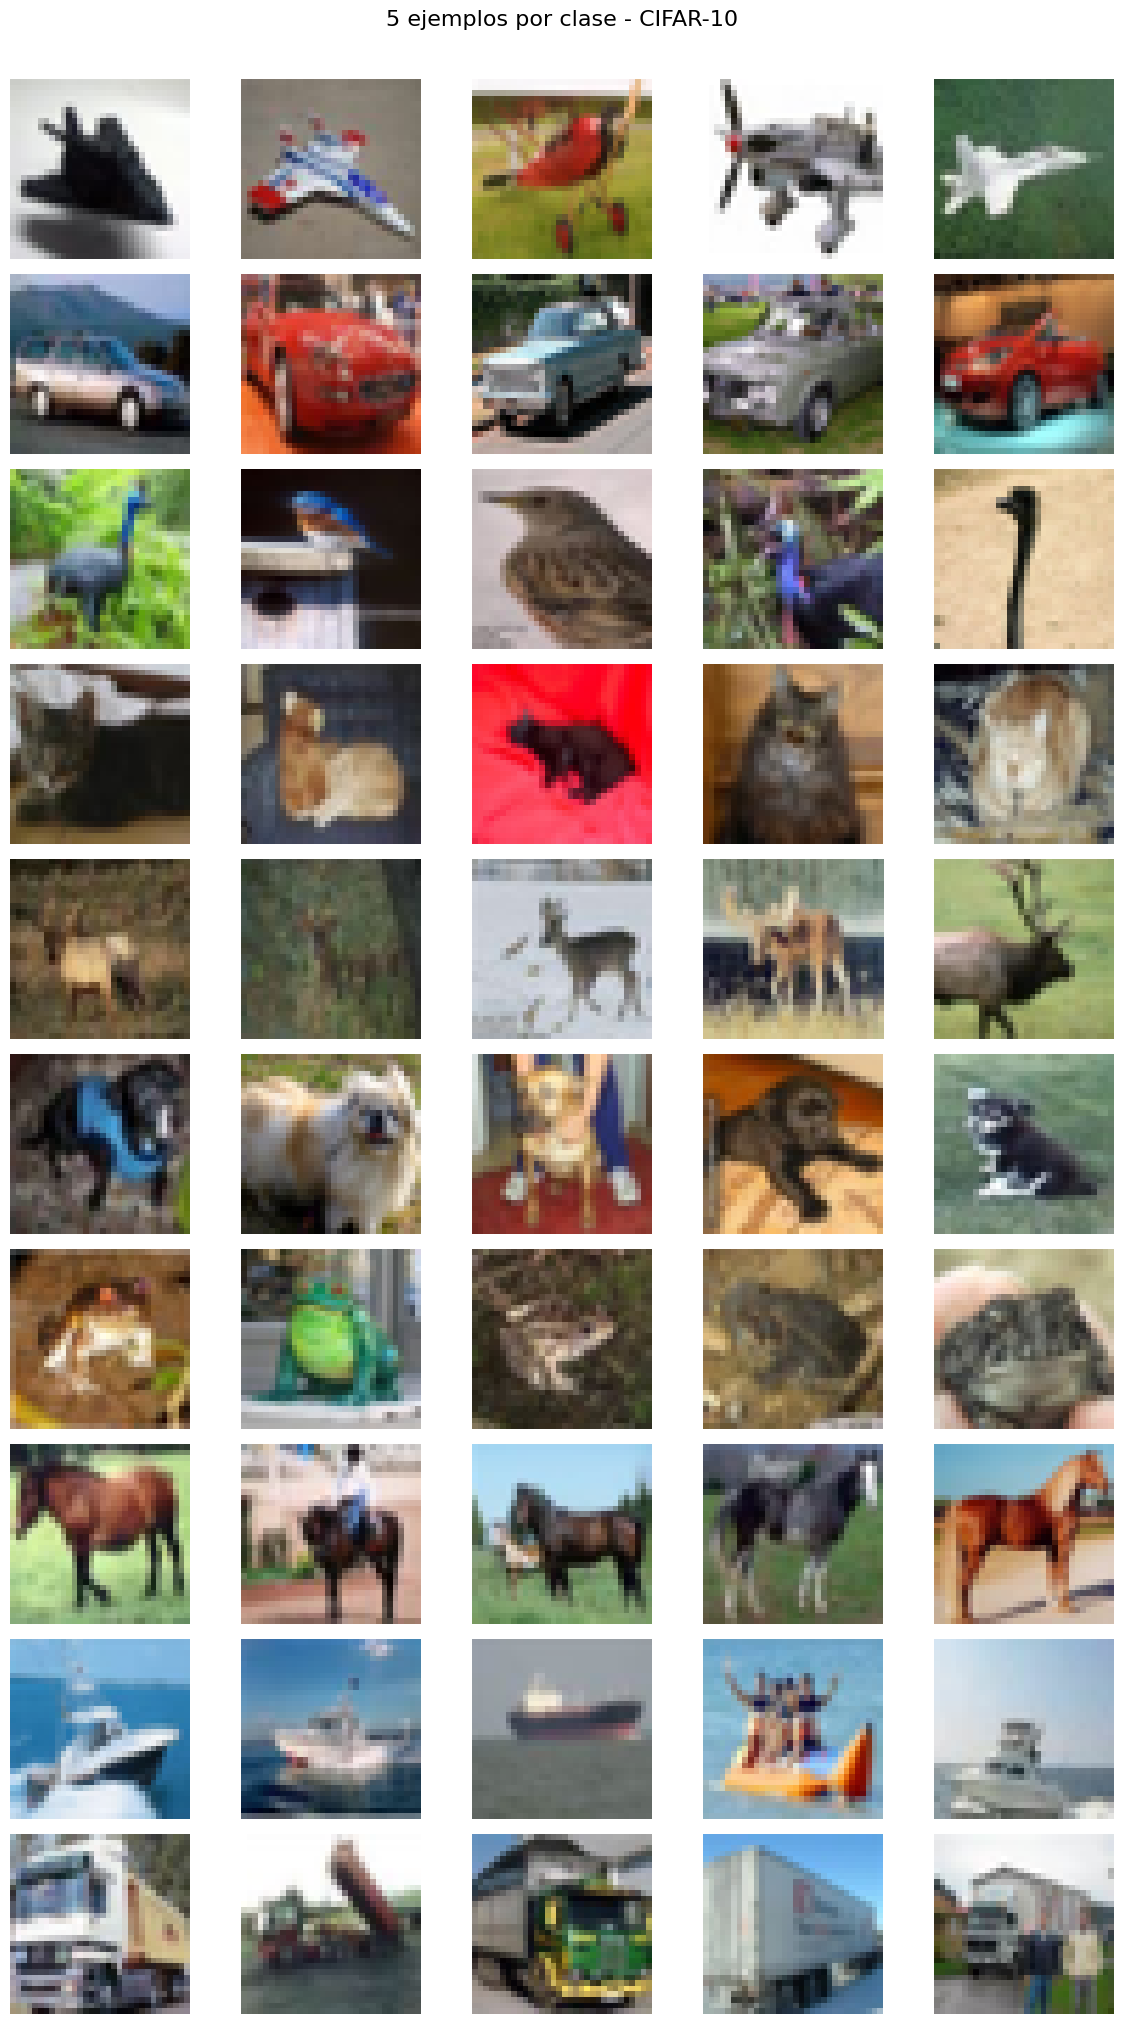

In [7]:
#ejemplos por calse
fig, axes = plt.subplots(10, 5, figsize=(12, 20))
fig.suptitle("5 ejemplos por clase - CIFAR-10", fontsize=16, y=1.01)

indices_by_class = {i: [] for i in range(10)}
for idx, label in enumerate(train_labels):
    if len(indices_by_class[label]) < 5:
        indices_by_class[label].append(idx)

for cls_idx in range(10):
    for j, img_idx in enumerate(indices_by_class[cls_idx]):
        img, _ = train_raw[img_idx]
        axes[cls_idx, j].imshow(img)
        axes[cls_idx, j].axis("off")
        if j == 0:
            axes[cls_idx, j].set_ylabel(classes[cls_idx], fontsize=11, rotation=0, labelpad=40, va="center")
plt.tight_layout()
plt.show()

In [8]:
#pipelines y splits
"""
Media por canal CIFAR-10: [0.4914009  0.48215896 0.4465308 ]
Std por canal CIFAR-10:   [0.24703279 0.24348423 0.26158753]
"""
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

#CNN 32×32
train_transform_cnn = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])
eval_transform_cnn = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

#VGG-16 128×128
IMG_SIZE_VGG = 128
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform_vgg = transforms.Compose([
    transforms.Resize((IMG_SIZE_VGG, IMG_SIZE_VGG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(IMG_SIZE_VGG, padding=8),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])
eval_transform_vgg = transforms.Compose([
    transforms.Resize((IMG_SIZE_VGG, IMG_SIZE_VGG)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print(f"Pixeles 32×32: {32*32}")
print(f"Pixeles 224×224: {224*224} -> factor {224*224/(32*32):.1f}x")
print(f"Pixeles {IMG_SIZE_VGG}×{IMG_SIZE_VGG}: {IMG_SIZE_VGG**2} -> factor {(IMG_SIZE_VGG**2)/(32*32):.1f}x")

#split estratificado 45000/5000
train_idx, val_idx = train_test_split(
    np.arange(len(train_raw)),
    test_size=5000,
    stratify=train_labels,
    random_state=SEED
)
print(f"Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_raw)}")

Pixeles 32×32: 1024
Pixeles 224×224: 50176 -> factor 49.0x
Pixeles 128×128: 16384 -> factor 16.0x
Train: 45000, Val: 5000, Test: 10000


In [9]:
#dataloaders
BATCH_SIZE = 64
PIN = torch.cuda.is_available()

def get_loaders(transform_train, transform_eval, batch_size=64, num_workers=2):
    train_ds = datasets.CIFAR10("./data", train=True, download=False, transform=transform_train)
    eval_ds  = datasets.CIFAR10("./data", train=True, download=False, transform=transform_eval)
    test_ds  = datasets.CIFAR10("./data", train=False, download=False, transform=transform_eval)

    train_subset = Subset(train_ds, train_idx)
    val_subset   = Subset(eval_ds, val_idx)

    return (
        DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                   num_workers=num_workers, pin_memory=PIN),
        DataLoader(val_subset, batch_size=batch_size, shuffle=False,
                   num_workers=num_workers, pin_memory=PIN),
        DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                   num_workers=num_workers, pin_memory=PIN),
    )

train_loader_cnn, val_loader_cnn, test_loader_cnn = get_loaders(
    train_transform_cnn, eval_transform_cnn, BATCH_SIZE)
train_loader_vgg, val_loader_vgg, test_loader_vgg = get_loaders(
    train_transform_vgg, eval_transform_vgg, BATCH_SIZE)

print(f"DataLoaders listos")
print(f" - Train CNN: {len(train_loader_cnn)} batches")
print(f" - Val CNN: {len(val_loader_cnn)} batches")
print(f" - Test CNN: {len(test_loader_cnn)} batches")

DataLoaders listos
 - Train CNN: 704 batches
 - Val CNN: 79 batches
 - Test CNN: 157 batches


In [10]:
#CNN desde 0
class CNNFromScratch(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.block1 = nn.Sequential(  #32-16
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block2 = nn.Sequential(  #16-8
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block3 = nn.Sequential(  #8-4
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)

#test
m = CNNFromScratch().to(device)
dummy = torch.randn(2, 3, 32, 32).to(device)
print(f"Salida: {m(dummy).shape}")
total, trainable = sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"Params: {total} | Entrenables: {trainable}")

Salida: torch.Size([2, 10])
Params: 323498 | Entrenables: 323498


In [11]:
#entrenamiento y eval
def train_one_epoch(model, loader, criterion, optimizer, device, use_amp=False):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    use_amp = use_amp and torch.cuda.is_available()
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    for inputs, targets in loader:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []

    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        running_loss += loss.item() * inputs.size(0)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    return {
        "loss": running_loss / len(all_targets),
        "accuracy": accuracy_score(all_targets, all_preds),
        "precision": precision_score(all_targets, all_preds, average="macro", zero_division=0),
        "recall": recall_score(all_targets, all_preds, average="macro", zero_division=0),
        "f1": f1_score(all_targets, all_preds, average="macro", zero_division=0),
    }, all_preds, all_targets


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def train_model(model, train_loader, val_loader, config, device, use_amp=False, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        config["param_groups"] if "param_groups" in config else model.parameters(),
        lr=config.get("lr", 1e-3),
        weight_decay=config.get("weight_decay", 1e-4),
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"])

    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc",
                                "val_f1", "val_precision", "val_recall", "epoch_time"]}

    best_f1 = 0.0
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    total_start = time.time()

    for epoch in range(config["epochs"]):
        torch.cuda.synchronize()
        t0 = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device, use_amp)
        val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        torch.cuda.synchronize()
        epoch_time = time.time() - t0

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["f1"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["epoch_time"].append(epoch_time)

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

        if verbose:
            print(f"Epoch {epoch+1:2d}/{config['epochs']} | "
                  f"TrainLoss {train_loss:.4f} Acc {train_acc:.4f} | "
                  f"ValLoss {val_metrics['loss']:.4f} "
                  f"Acc {val_metrics['accuracy']:.4f} "
                  f"F1 {val_metrics['f1']:.4f} | "
                  f"{epoch_time:.1f}s")

    total_time = time.time() - total_start
    peak_mem = torch.cuda.max_memory_allocated() / 1e9

    model.load_state_dict(best_state)
    history.update({
        "total_time": total_time,
        "peak_memory_gb": peak_mem,
        "best_epoch": best_epoch,
        "best_f1": best_f1,
    })
    return model, history

In [12]:
#vgg16 fauter extrac/finetuning
def build_vgg16(mode="feature_extraction", num_unfreeze_blocks=0, num_classes=10):
    weights = VGG16_Weights.IMAGENET1K_V1
    model = models.vgg16(weights=weights)

    # Congelar TODO primero
    for param in model.parameters():
        param.requires_grad = False

    # Reemplazar classifier[6]
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, num_classes)

    # Descongelar bloques para fine-tuning
    if mode == "fine_tuning" and num_unfreeze_blocks > 0:
        block_ranges = {
            5: list(range(24, 31)),
            4: list(range(17, 31)),
            3: list(range(10, 31)),
        }
        for idx in block_ranges.get(num_unfreeze_blocks, []):
            for param in model.features[idx].parameters():
                param.requires_grad = True

    return model


def report(model, name):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name:8s} -> Total: {total:>12} | Entrenables: {train:>12}")


print("=== VERIFICACION PARAMETROS ===")
report(build_vgg16("feature_extraction"), "FE")
report(build_vgg16("fine_tuning", 1), "FT-1blk")
report(build_vgg16("fine_tuning", 2), "FT-2blk")
report(build_vgg16("fine_tuning", 3), "FT-3blk")

=== VERIFICACION PARAMETROS ===
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 178MB/s]


FE       -> Total:    134301514 | Entrenables:        40970
FT-1blk  -> Total:    134301514 | Entrenables:        40970
FT-2blk  -> Total:    134301514 | Entrenables:        40970
FT-3blk  -> Total:    134301514 | Entrenables:     14495498


In [13]:
#Eentramiento 3tiersw
print("=== ENTRENAMIENTO CNN ===")

cnn_configs = [
    {"name": "CNN_iter1", "lr": 1e-3, "weight_decay": 1e-4, "epochs": 20},
    {"name": "CNN_iter2", "lr": 5e-4, "weight_decay": 1e-4, "epochs": 20},
    {"name": "CNN_iter3", "lr": 1e-3, "weight_decay": 1e-3, "epochs": 20},
]

cnn_results = {}
for cfg in cnn_configs:
    print(f"\n{'='*60}\n{cfg['name']}\n{'='*60}")
    model = CNNFromScratch().to(device)
    total, trainable = count_parameters(model)
    print(f"Params totales: {total:,} | Entrenables: {trainable:,}")

    model, hist = train_model(model, train_loader_cnn, val_loader_cnn,
                              cfg, device, use_amp=True)
    hist["total_params"] = total
    hist["trainable_params"] = trainable
    hist["config"] = cfg
    cnn_results[cfg["name"]] = hist
    torch.save(model.state_dict(), f"{cfg['name']}.pth")

=== ENTRENAMIENTO CNN ===

CNN_iter1
Params totales: 323,498 | Entrenables: 323,498
Epoch  1/20 | TrainLoss 1.5457 Acc 0.4182 | ValLoss 1.3044 Acc 0.5310 F1 0.5264 | 30.9s
Epoch  2/20 | TrainLoss 1.1472 Acc 0.5861 | ValLoss 1.0058 Acc 0.6392 F1 0.6180 | 35.5s
Epoch  3/20 | TrainLoss 0.9840 Acc 0.6516 | ValLoss 0.8489 Acc 0.6900 F1 0.6847 | 29.6s
Epoch  4/20 | TrainLoss 0.8771 Acc 0.6923 | ValLoss 0.8319 Acc 0.7068 F1 0.7141 | 29.8s
Epoch  5/20 | TrainLoss 0.8011 Acc 0.7217 | ValLoss 0.7088 Acc 0.7558 F1 0.7565 | 31.3s
Epoch  6/20 | TrainLoss 0.7305 Acc 0.7501 | ValLoss 0.6249 Acc 0.7856 F1 0.7858 | 29.8s
Epoch  7/20 | TrainLoss 0.6849 Acc 0.7669 | ValLoss 0.6119 Acc 0.7938 F1 0.7946 | 29.6s
Epoch  8/20 | TrainLoss 0.6442 Acc 0.7822 | ValLoss 0.5925 Acc 0.8006 F1 0.7982 | 31.0s
Epoch  9/20 | TrainLoss 0.6052 Acc 0.7935 | ValLoss 0.5229 Acc 0.8242 F1 0.8247 | 30.1s
Epoch 10/20 | TrainLoss 0.5707 Acc 0.8082 | ValLoss 0.5438 Acc 0.8242 F1 0.8269 | 29.6s
Epoch 11/20 | TrainLoss 0.5406 Acc 0

In [14]:
#entrenamiento vgg16
print("=== ENTRENAMIENTO VGG-16 FEATURE EXTRACTION ===")

vgg_fe_configs = [
    {"name": "VGG_FE_iter1", "lr": 1e-3, "weight_decay": 1e-4, "epochs": 10},
    {"name": "VGG_FE_iter2", "lr": 5e-4, "weight_decay": 1e-4, "epochs": 10},
    {"name": "VGG_FE_iter3", "lr": 2e-3, "weight_decay": 1e-3, "epochs": 10},
]

vgg_fe_results = {}
for cfg in vgg_fe_configs:
    print(f"\n{'='*60}\n{cfg['name']}\n{'='*60}")
    model = build_vgg16("feature_extraction").to(device)
    total, trainable = count_parameters(model)
    print(f"Params totales: {total} | Entrenables: {trainable}")

    model, hist = train_model(model, train_loader_vgg, val_loader_vgg, cfg, device, use_amp=True)
    hist["total_params"] = total
    hist["trainable_params"] = trainable
    hist["config"] = cfg
    vgg_fe_results[cfg["name"]] = hist
    torch.save(model.state_dict(), f"{cfg['name']}.pth")

=== ENTRENAMIENTO VGG-16 FEATURE EXTRACTION ===

VGG_FE_iter1
Params totales: 134301514 | Entrenables: 40970
Epoch  1/10 | TrainLoss 0.7540 Acc 0.7448 | ValLoss 0.5637 Acc 0.8050 F1 0.8017 | 85.1s
Epoch  2/10 | TrainLoss 0.7281 Acc 0.7641 | ValLoss 0.5469 Acc 0.8110 F1 0.8102 | 85.4s
Epoch  3/10 | TrainLoss 0.7314 Acc 0.7649 | ValLoss 0.5428 Acc 0.8184 F1 0.8161 | 85.9s
Epoch  4/10 | TrainLoss 0.7266 Acc 0.7675 | ValLoss 0.5523 Acc 0.8136 F1 0.8104 | 86.1s
Epoch  5/10 | TrainLoss 0.6892 Acc 0.7722 | ValLoss 0.5086 Acc 0.8266 F1 0.8255 | 84.9s
Epoch  6/10 | TrainLoss 0.6785 Acc 0.7756 | ValLoss 0.5280 Acc 0.8204 F1 0.8181 | 84.5s
Epoch  7/10 | TrainLoss 0.6462 Acc 0.7836 | ValLoss 0.5087 Acc 0.8204 F1 0.8182 | 86.5s
Epoch  8/10 | TrainLoss 0.6164 Acc 0.7903 | ValLoss 0.4786 Acc 0.8350 F1 0.8329 | 86.2s
Epoch  9/10 | TrainLoss 0.5962 Acc 0.7947 | ValLoss 0.4876 Acc 0.8330 F1 0.8303 | 85.7s
Epoch 10/10 | TrainLoss 0.5860 Acc 0.7982 | ValLoss 0.4756 Acc 0.8358 F1 0.8335 | 85.2s

VGG_FE_ite

In [15]:
#3 iter fine tuning
print("=== ENTRENAMIENTO VGG-16 FINE-TUNING ===")

vgg_ft_configs = [
    {"name": "VGG_FT_1block",  "unfreeze": 1, "lr_head": 1e-3,
     "lr_backbone": 1e-4, "weight_decay": 1e-4, "epochs": 10},
    {"name": "VGG_FT_2blocks", "unfreeze": 2, "lr_head": 1e-3,
     "lr_backbone": 1e-4, "weight_decay": 1e-4, "epochs": 10},
    {"name": "VGG_FT_3blocks", "unfreeze": 3, "lr_head": 1e-3,
     "lr_backbone": 1e-5, "weight_decay": 1e-4, "epochs": 10}
]

vgg_ft_results = {}
for cfg in vgg_ft_configs:
    print(f"\n{'='*60}\n{cfg['name']} (descongelando {cfg['unfreeze']} bloques)\n{'='*60}")
    model = build_vgg16("fine_tuning", num_unfreeze_blocks=cfg["unfreeze"]).to(device)
    total, trainable = count_parameters(model)
    print(f"Params totales: {total} | Entrenables: {trainable}")

    backbone_params = [p for n, p in model.named_parameters()
                       if p.requires_grad and n.startswith("features")]
    head_params = [p for n, p in model.named_parameters()
                   if p.requires_grad and n.startswith("classifier")]

    train_cfg = {
        "epochs": cfg["epochs"],
        "weight_decay": cfg["weight_decay"],
        "param_groups": [
            {"params": backbone_params, "lr": cfg["lr_backbone"]},
            {"params": head_params,     "lr": cfg["lr_head"]}
        ],
    }

    model, hist = train_model(model, train_loader_vgg, val_loader_vgg, train_cfg, device, use_amp=True)
    hist["total_params"] = total
    hist["trainable_params"] = trainable
    hist["config"] = cfg
    vgg_ft_results[cfg["name"]] = hist
    torch.save(model.state_dict(), f"{cfg['name']}.pth")

=== ENTRENAMIENTO VGG-16 FINE-TUNING ===

VGG_FT_1block (descongelando 1 bloques)
Params totales: 134301514 | Entrenables: 40970
Epoch  1/10 | TrainLoss 0.7538 Acc 0.7444 | ValLoss 0.6154 Acc 0.7920 F1 0.7871 | 86.9s
Epoch  2/10 | TrainLoss 0.7260 Acc 0.7630 | ValLoss 0.5714 Acc 0.8044 F1 0.8021 | 86.3s
Epoch  3/10 | TrainLoss 0.7231 Acc 0.7640 | ValLoss 0.5528 Acc 0.8192 F1 0.8164 | 86.1s
Epoch  4/10 | TrainLoss 0.7175 Acc 0.7704 | ValLoss 0.5274 Acc 0.8208 F1 0.8186 | 85.7s
Epoch  5/10 | TrainLoss 0.6911 Acc 0.7747 | ValLoss 0.5009 Acc 0.8260 F1 0.8243 | 85.0s
Epoch  6/10 | TrainLoss 0.6642 Acc 0.7795 | ValLoss 0.5201 Acc 0.8196 F1 0.8172 | 85.5s
Epoch  7/10 | TrainLoss 0.6397 Acc 0.7844 | ValLoss 0.4865 Acc 0.8270 F1 0.8256 | 86.1s
Epoch  8/10 | TrainLoss 0.6199 Acc 0.7891 | ValLoss 0.5127 Acc 0.8188 F1 0.8150 | 86.7s
Epoch  9/10 | TrainLoss 0.6031 Acc 0.7927 | ValLoss 0.4792 Acc 0.8318 F1 0.8297 | 85.7s
Epoch 10/10 | TrainLoss 0.5914 Acc 0.7968 | ValLoss 0.4758 Acc 0.8332 F1 0.8311

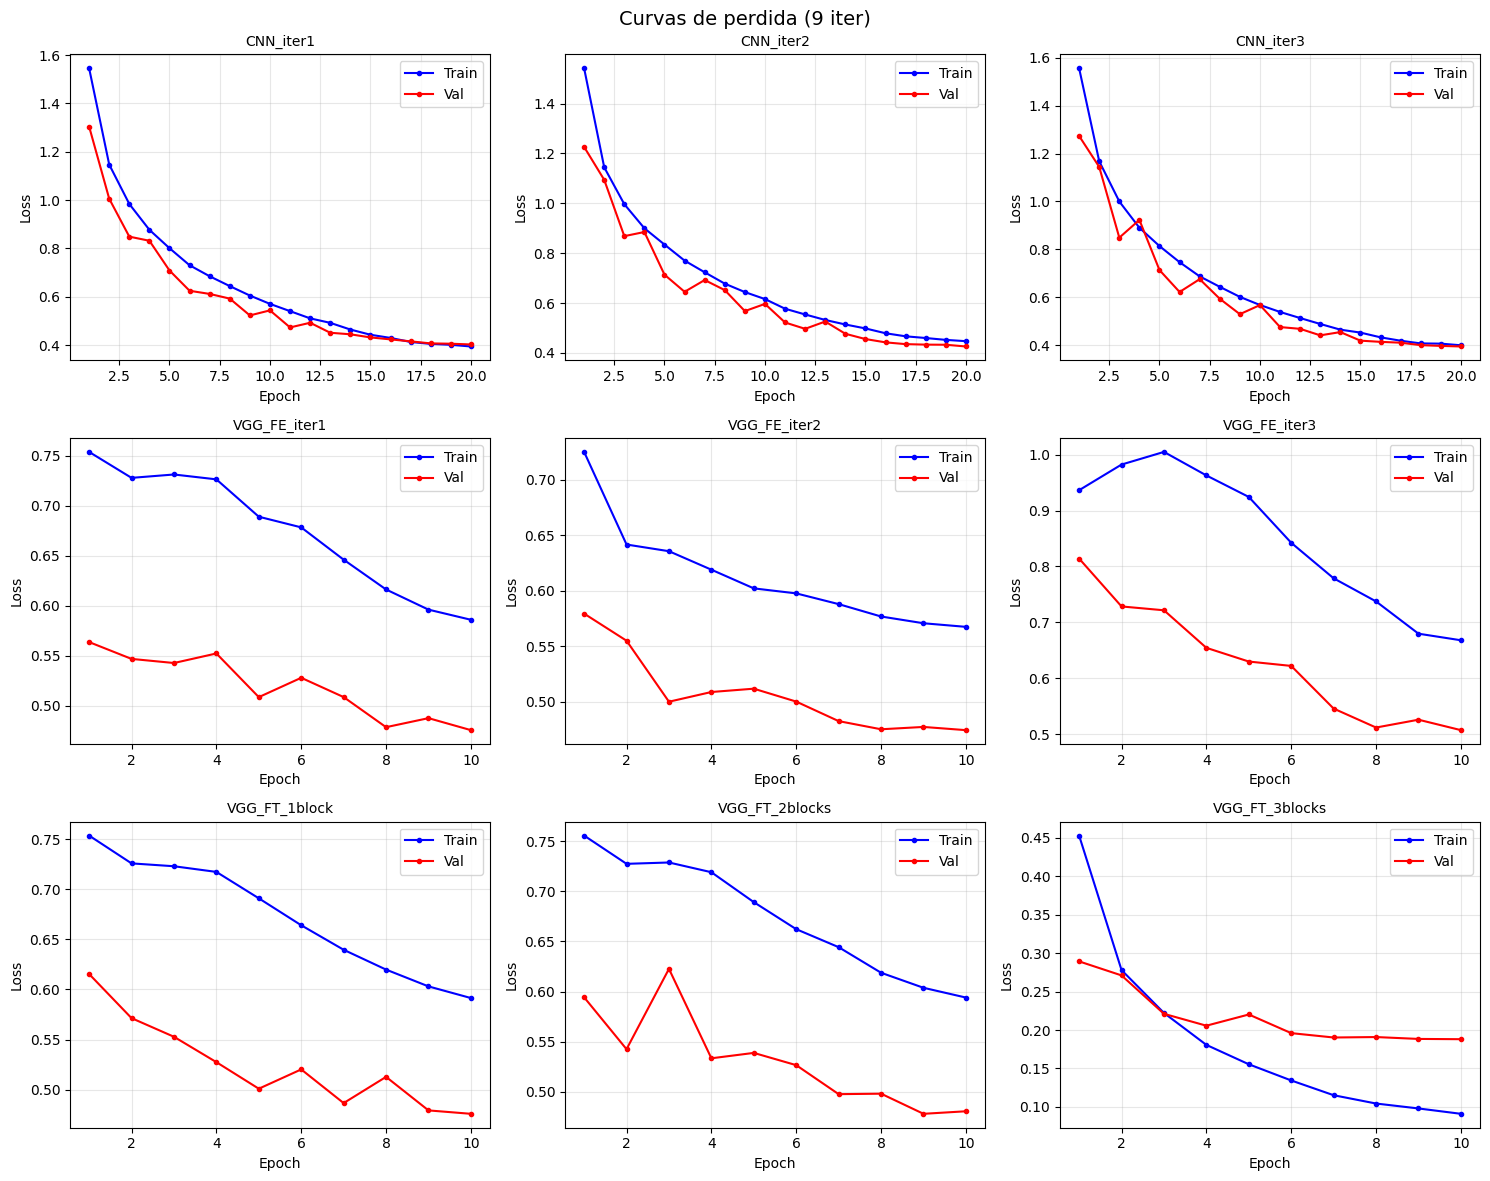

In [16]:
#curvas perdida
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
all_results = [cnn_results, vgg_fe_results, vgg_ft_results]
titles = ["CNN desde cero", "VGG-16 Feature Extraction", "VGG-16 Fine-Tuning"]

for row, (results, title) in enumerate(zip(all_results, titles)):
    for col, (name, hist) in enumerate(results.items()):
        ax = axes[row, col]
        epochs = range(1, len(hist["train_loss"]) + 1)
        ax.plot(epochs, hist["train_loss"], "b-o", label="Train", markersize=3)
        ax.plot(epochs, hist["val_loss"], "r-o", label="Val", markersize=3)
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Curvas de perdida (9 iter)", fontsize=14)
plt.tight_layout()
plt.savefig("loss_curves.png", dpi=100, bbox_inches="tight")
plt.show()

In [17]:
#eval final test
def get_best_model_name(results):
    return max(results.items(), key=lambda x: x[1]["best_f1"])[0]

best_cnn_name = get_best_model_name(cnn_results)
best_fe_name  = get_best_model_name(vgg_fe_results)
best_ft_name  = get_best_model_name(vgg_ft_results)
print(f"Mejores: {best_cnn_name}, {best_fe_name}, {best_ft_name}")


def final_evaluation(model, loader, device, name):
    metrics, preds, targets = evaluate(model, loader, nn.CrossEntropyLoss(), device)
    print(f"\n--- {name} ---")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")
    return metrics, preds, targets


test_results = {}

#CNN
cnn_best = CNNFromScratch().to(device)
cnn_best.load_state_dict(torch.load(f"{best_cnn_name}.pth", map_location=device, weights_only=True))
test_results["CNN"] = final_evaluation(cnn_best, test_loader_cnn, device, best_cnn_name)

#VGG16 FE
vgg_fe_best = build_vgg16("feature_extraction").to(device)
vgg_fe_best.load_state_dict(torch.load(f"{best_fe_name}.pth", map_location=device, weights_only=True))
test_results["VGG_FE"] = final_evaluation(vgg_fe_best, test_loader_vgg, device, best_fe_name)

#VGG16 FT
ft_unfreeze = vgg_ft_results[best_ft_name]["config"]["unfreeze"]
vgg_ft_best = build_vgg16("fine_tuning", num_unfreeze_blocks=ft_unfreeze).to(device)
vgg_ft_best.load_state_dict(torch.load(f"{best_ft_name}.pth", map_location=device, weights_only=True))
test_results["VGG_FT"] = final_evaluation(vgg_ft_best, test_loader_vgg, device, best_ft_name)

Mejores: CNN_iter3, VGG_FE_iter1, VGG_FT_3blocks

--- CNN_iter3 ---
  loss: 0.4133
  accuracy: 0.8619
  precision: 0.8615
  recall: 0.8619
  f1: 0.8615

--- VGG_FE_iter1 ---
  loss: 0.5004
  accuracy: 0.8264
  precision: 0.8297
  recall: 0.8264
  f1: 0.8237

--- VGG_FT_3blocks ---
  loss: 0.2124
  accuracy: 0.9355
  precision: 0.9353
  recall: 0.9355
  f1: 0.9352


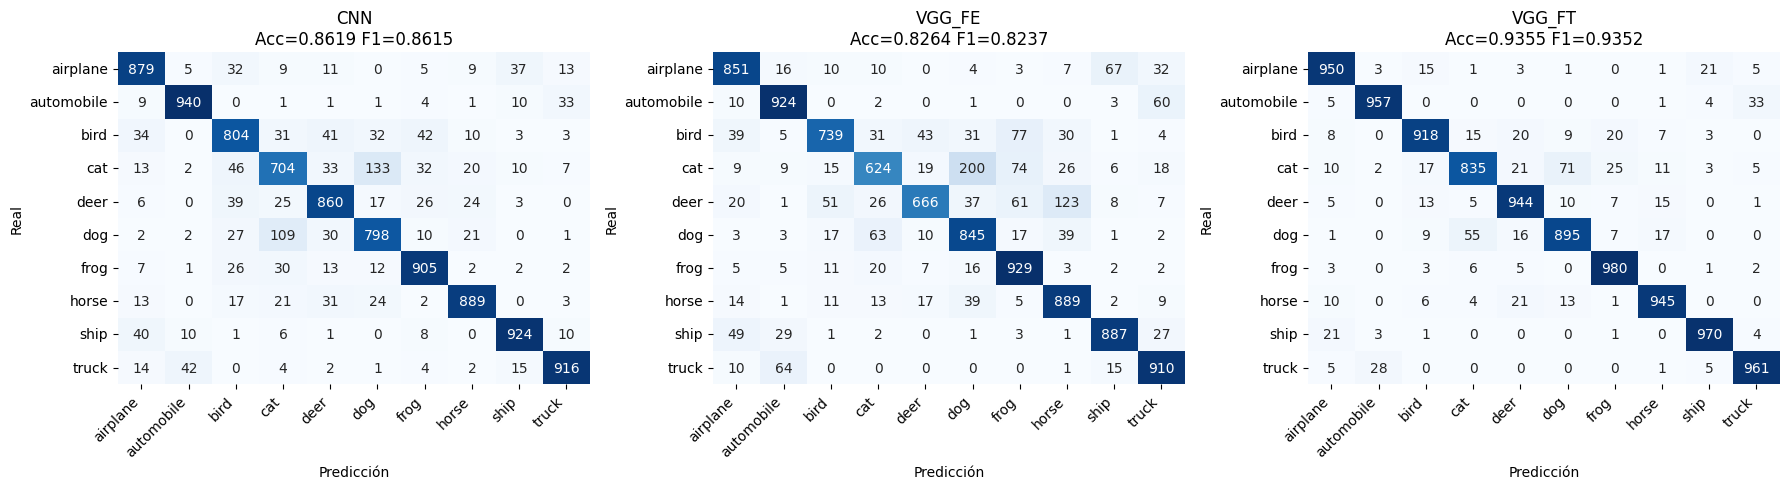

In [18]:
#matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (metrics, preds, targets)) in zip(axes, test_results.items()):
    cm = confusion_matrix(targets, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=classes, yticklabels=classes, cbar=False)
    ax.set_title(f"{name}\nAcc={metrics['accuracy']:.4f} F1={metrics['f1']:.4f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=100, bbox_inches="tight")
plt.show()

In [19]:
# ============================================================
# CELDA 17: FLOPs, LATENCIA Y TABLA COMPARATIVA
# ============================================================
def measure_inference_cost(model, input_size, device, n_runs=50):
    model.eval()
    dummy = torch.randn(1, *input_size).to(device)

    # FLOPs con fvcore
    flops = FlopCountAnalysis(model, dummy).total()
    macs = flops / 2  # MACs ≈ FLOPs / 2

    # Latencia
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy)
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_runs):
            _ = model(dummy)
        torch.cuda.synchronize()
        latency = (time.time() - t0) / n_runs * 1000  # ms

    return macs, flops, latency


resource_table = []

# CNN
macs_c, flops_c, lat_c = measure_inference_cost(cnn_best, (3, 32, 32), device)
total_c, train_c = count_parameters(cnn_best)
resource_table.append({
    "Modelo": "CNN desde cero",
    "Params totales": total_c, "Params entrenables": train_c,
    "MACs (G)": macs_c/1e9, "FLOPs (G)": flops_c/1e9,
    "Latencia (ms)": lat_c,
    "Mejor epoch": cnn_results[best_cnn_name]["best_epoch"],
    "Tiempo total (s)": cnn_results[best_cnn_name]["total_time"],
    "Memoria pico (GB)": cnn_results[best_cnn_name]["peak_memory_gb"],
    "Test Acc": test_results["CNN"][0]["accuracy"],
    "Test F1":  test_results["CNN"][0]["f1"],
})

# VGG FE
macs_f, flops_f, lat_f = measure_inference_cost(vgg_fe_best, (3, IMG_SIZE_VGG, IMG_SIZE_VGG), device)
total_f, train_f = count_parameters(vgg_fe_best)
resource_table.append({
    "Modelo": "VGG-16 Feature Extraction",
    "Params totales": total_f, "Params entrenables": train_f,
    "MACs (G)": macs_f/1e9, "FLOPs (G)": flops_f/1e9,
    "Latencia (ms)": lat_f,
    "Mejor epoch": vgg_fe_results[best_fe_name]["best_epoch"],
    "Tiempo total (s)": vgg_fe_results[best_fe_name]["total_time"],
    "Memoria pico (GB)": vgg_fe_results[best_fe_name]["peak_memory_gb"],
    "Test Acc": test_results["VGG_FE"][0]["accuracy"],
    "Test F1":  test_results["VGG_FE"][0]["f1"],
})

# VGG FT
macs_t, flops_t, lat_t = measure_inference_cost(vgg_ft_best, (3, IMG_SIZE_VGG, IMG_SIZE_VGG), device)
total_t, train_t = count_parameters(vgg_ft_best)
resource_table.append({
    "Modelo": "VGG-16 Fine-Tuning",
    "Params totales": total_t, "Params entrenables": train_t,
    "MACs (G)": macs_t/1e9, "FLOPs (G)": flops_t/1e9,
    "Latencia (ms)": lat_t,
    "Mejor epoch": vgg_ft_results[best_ft_name]["best_epoch"],
    "Tiempo total (s)": vgg_ft_results[best_ft_name]["total_time"],
    "Memoria pico (GB)": vgg_ft_results[best_ft_name]["peak_memory_gb"],
    "Test Acc": test_results["VGG_FT"][0]["accuracy"],
    "Test F1":  test_results["VGG_FT"][0]["f1"],
})

df_resources = pd.DataFrame(resource_table)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("\n" + "="*80)
print("TABLA COMPARATIVA RENDIMIENTO Y RECURSOS")
print("="*80)
print(df_resources.to_string(index=False))
df_resources.to_csv("tabla_recursos.csv", index=False)
print("\nCSV creado")


TABLA COMPARATIVA RENDIMIENTO Y RECURSOS
                   Modelo  Params totales  Params entrenables  MACs (G)  FLOPs (G)  Latencia (ms)  Mejor epoch  Tiempo total (s)  Memoria pico (GB)  Test Acc  Test F1
           CNN desde cero          323498              323498    0.0195     0.0389         0.9239           20          603.3822             0.1484    0.8619   0.8615
VGG-16 Feature Extraction       134301514               40970    2.5654     5.1307         8.4017           10          855.5301             2.8541    0.8264   0.8237
       VGG-16 Fine-Tuning       134301514            14495498    2.5654     5.1307         7.6932            9          987.2501             3.0327    0.9355   0.9352

CSV creado


In [20]:
# ============================================================
# CELDA 18: EXPERIMENTO 4.1 — EFECTO DE LA CANTIDAD DE DATOS
# ============================================================
print("=== EXPERIMENTO: 10% DE DATOS ===")

def get_fraction_loaders(train_idx_full, labels_full, fraction=0.1):
    n_total = len(train_idx_full)
    n_frac = int(n_total * fraction)

    # Submuestra estratificada (train_size como float)
    train_frac_idx, _ = train_test_split(
        train_idx_full,
        train_size=n_frac,
        stratify=labels_full[train_idx_full],
        random_state=SEED,
    )

    train_ds_cnn = datasets.CIFAR10("./data", train=True, transform=train_transform_cnn)
    train_ds_vgg = datasets.CIFAR10("./data", train=True, transform=train_transform_vgg)
    test_ds_cnn  = datasets.CIFAR10("./data", train=False, transform=eval_transform_cnn)
    test_ds_vgg  = datasets.CIFAR10("./data", train=False, transform=eval_transform_vgg)

    train_frac_cnn = Subset(train_ds_cnn, train_frac_idx)
    train_frac_vgg = Subset(train_ds_vgg, train_frac_idx)

    return (
        DataLoader(train_frac_cnn, batch_size=BATCH_SIZE, shuffle=True,
                   num_workers=2, pin_memory=PIN),
        DataLoader(train_frac_vgg, batch_size=BATCH_SIZE, shuffle=True,
                   num_workers=2, pin_memory=PIN),
        DataLoader(test_ds_cnn, batch_size=BATCH_SIZE, shuffle=False,
                   num_workers=2, pin_memory=PIN),
        DataLoader(test_ds_vgg, batch_size=BATCH_SIZE, shuffle=False,
                   num_workers=2, pin_memory=PIN),
    )


train_labels_np = np.array(train_labels)
tr_frac_cnn, tr_frac_vgg, te_cnn, te_vgg = get_fraction_loaders(
    train_idx, train_labels_np, fraction=0.1)
print(f"Imágenes en fracción 10%: {len(tr_frac_cnn.dataset)}")

fraction_results = {}

#CNN 10%
print("\n--- CNN 10% ---")
cnn_frac_cfg = cnn_results[best_cnn_name]["config"]
cnn_frac = CNNFromScratch().to(device)
_, hist_cnn_frac = train_model(cnn_frac, tr_frac_cnn, val_loader_cnn, cnn_frac_cfg, device, use_amp=True, verbose=False)
m_cnn_frac, _, _ = evaluate(cnn_frac, test_loader_cnn, nn.CrossEntropyLoss(), device)
fraction_results["CNN"] = m_cnn_frac

#VGG16 FE 10%
print("\n--- VGG FE 10% ---")
fe_frac_cfg = vgg_fe_results[best_fe_name]["config"]
vgg_fe_frac = build_vgg16("feature_extraction").to(device)
_, hist_fe_frac = train_model(vgg_fe_frac, tr_frac_vgg, val_loader_vgg, fe_frac_cfg, device, use_amp=True, verbose=False)
m_fe_frac, _, _ = evaluate(vgg_fe_frac, test_loader_vgg, nn.CrossEntropyLoss(), device)
fraction_results["VGG_FE"] = m_fe_frac

#VGG16 FT 10%
print("\n--- VGG FT 10% ---")
ft_frac_cfg = vgg_ft_results[best_ft_name]["config"]
vgg_ft_frac = build_vgg16("fine_tuning", num_unfreeze_blocks=ft_frac_cfg["unfreeze"]).to(device)

backbone_frac = [p for n, p in vgg_ft_frac.named_parameters()
                 if p.requires_grad and n.startswith("features")]
head_frac = [p for n, p in vgg_ft_frac.named_parameters()
             if p.requires_grad and n.startswith("classifier")]

train_cfg_frac = {
    "epochs": ft_frac_cfg["epochs"],
    "weight_decay": ft_frac_cfg["weight_decay"],
    "param_groups": [
        {"params": backbone_frac, "lr": ft_frac_cfg["lr_backbone"]},
        {"params": head_frac,     "lr": ft_frac_cfg["lr_head"]},
    ],
}

_, hist_ft_frac = train_model(vgg_ft_frac, tr_frac_vgg, val_loader_vgg,
                              train_cfg_frac, device, use_amp=True, verbose=False)
m_ft_frac, _, _ = evaluate(vgg_ft_frac, test_loader_vgg, nn.CrossEntropyLoss(), device)
fraction_results["VGG_FT"] = m_ft_frac

print("\n" + "="*60)
print("100% vs 10% DATOS")
print("="*60)
print(f"{'Modelo':<20} {'100% Acc':>10} {'10% Acc':>10} {'Δ':>10}")
for name, full_metrics in [("CNN", test_results["CNN"][0]),
                            ("VGG_FE", test_results["VGG_FE"][0]),
                            ("VGG_FT", test_results["VGG_FT"][0])]:
    frac_acc = fraction_results[name]["accuracy"]
    delta = full_metrics["accuracy"] - frac_acc
    print(f"{name:<20} {full_metrics['accuracy']:>10.4f} {frac_acc:>10.4f} {delta:>10.4f}")

=== EXPERIMENTO: 10% DE DATOS ===
Imágenes en fracción 10%: 4500

--- CNN 10% ---

--- VGG FE 10% ---

--- VGG FT 10% ---

100% vs 10% DATOS
Modelo                 100% Acc    10% Acc          Δ
CNN                      0.8619     0.6542     0.2077
VGG_FE                   0.8264     0.7984     0.0280
VGG_FT                   0.9355     0.8778     0.0577


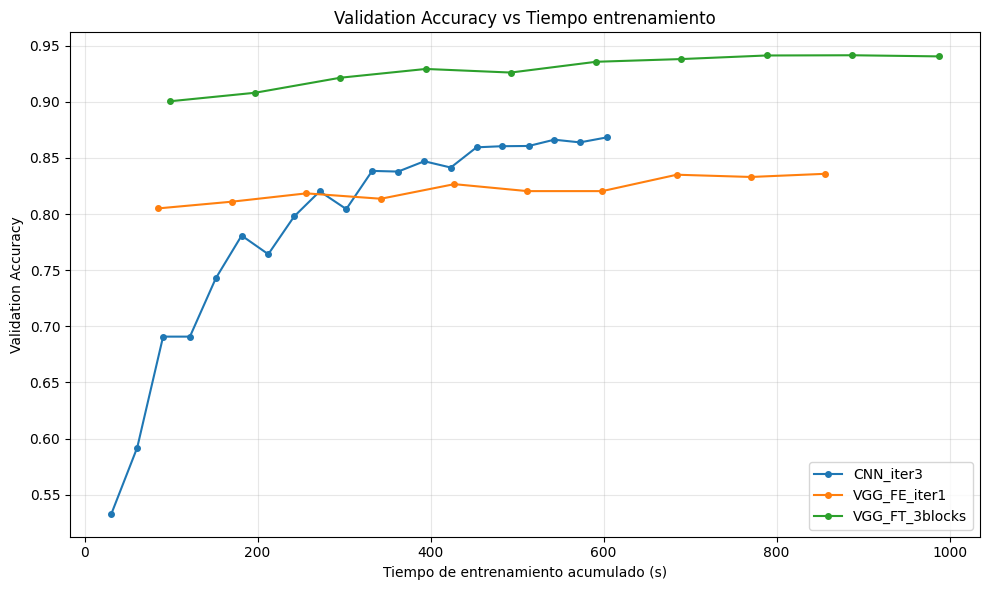

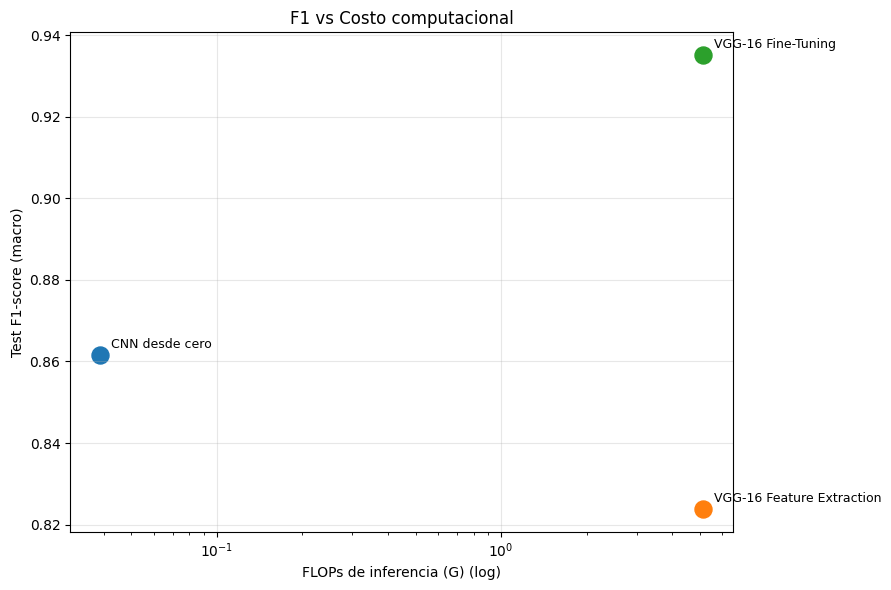

In [21]:
#graficas comparacion
fig, ax = plt.subplots(figsize=(10, 6))
for name, hist, color in [
    (best_cnn_name, cnn_results[best_cnn_name], "tab:blue"),
    (best_fe_name,  vgg_fe_results[best_fe_name],  "tab:orange"),
    (best_ft_name,  vgg_ft_results[best_ft_name],  "tab:green"),
]:
    times = np.cumsum(hist["epoch_time"])
    ax.plot(times, hist["val_acc"], "-o", label=name, color=color, markersize=4)
ax.set_xlabel("Tiempo de entrenamiento acumulado (s)")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Validation Accuracy vs Tiempo entrenamiento")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("val_acc_vs_time.png", dpi=100, bbox_inches="tight")
plt.show()

#Test F1 vs FLOPs inferencia
fig, ax = plt.subplots(figsize=(9, 6))
for row in resource_table:
    ax.scatter(row["FLOPs (G)"], row["Test F1"], s=150, label=row["Modelo"])
    ax.annotate(row["Modelo"], (row["FLOPs (G)"], row["Test F1"]), textcoords="offset points", xytext=(8, 5), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("FLOPs de inferencia (G) (log)")
ax.set_ylabel("Test F1-score (macro)")
ax.set_title("F1 vs Costo computacional")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("f1_vs_flops.png", dpi=100, bbox_inches="tight")
plt.show()

# 3. Investigación


*   torchvision.models.vgg16
modelo que construye el modelo de red neuronal vgg16
    - VGG16_Weights: maneja pesos preentrenados y transformaciones del modelo. Por default usa los mejores pesos mas recientes. Sus parametros reelevantes son weights (que pesos preentrenados va a usar) y progress (barra de descarga). Weights.transforms() devuelve pipeline de procesamiento que el modelo espera, dimensiona, hace recortes, convierte a tensor y normaliza.
*   Estructura del modelo
    - model.features: tipo nn.sequential, tiene capas convulcionales, ReLU y MaxPool. extrae características visuales.
    - model.avgpool (nn.AdaptiveAvfPool2d): reduce espacialmente a 7x7 (esto lo hace sin importar el input).
    - model.classifier: tambien nn.sequential, capas fully connected, hace la clasificación. Este es normalmente reemplazado por uno que sea bueno para la cantidad de clases que haya en el problema.
*   requires_grad: contrala los parametros que se usan en el training, al congelar las capas preentrenadas evita que se de algun cambio por los datos nuevos y no acumulan gradientes, para congelar se pone con parametro.requires_grad = False y para descongelar se pone como True.
*   model.train vs model.eval y torch.no_grad: model.train activa dropout y usa las estadisticas acumuladas en batch actual en batchNorm. moedl.eval lo desactiva y usa las estadisticas del BatchNorm, sive para inferencia y validacion. no_grad deshabilita el calculo de gradientes y reduce el consumo de meoria al no almacenar el grafo comutacional.
*   Grupos de parametros para learning rates distintos:
Aplica diferentes learning rates a distintas partes del modelo, de forma estandar el LR es para capas preentrenadas y uno grande para la cabeza nueva. cada uno tuene tener su propio lr, weight_decay, momentum, etc.
Ej.
```
optimizer = torch.optim.SGD([
    {'params': model.features.parameters(), 'lr': 1e-4},   # backbone
    {'params': model.classifier.parameters(), 'lr': 1e-2}  # cabeza
], momentum=0.9)
```
*  Herramientas para contar parametros y operaciones: torchinfo (genera un resumen con shapes, parametros por capa y opreacioens MACs/FLOPs esperados), fvcore (FlopCountAnalysis ayuda para FLOPs precisos y parameter_count para parametros) y thop y ptflops (Librerias con especializacion para profiling en MACs y FLOPs, necesitan una entrada dummy para trazar el grafo).

* Medicion de memoria y tiempo en GPU:
  - torch.cuda.synchronize(): Sincroniza CPU con GPU, es necesario antes de medir tiempo, porque las operaciones CUDA son asíncronas.
  - torch.cuda.max_memory_allocated(): Devuelve el pico de memoria que se dio en la ejecución.

*  MACs vs FLOPs:
  - Floating Point Operations: Operaciones de punto flotante totales (operaciones matematicas bases: +,-,*,/)
  - Multiply-Accumulate: Operaciones que combinan multiplicación y suma, por ejemplo 1 MAC = 2 FLOP

* Parametros totales vs entrenables:
  - Totales: Todos los pesos y biases del modelo, independientemente de si se actualizan
  - Entrenables: Solo los que tienen requires_grad=True. En transfer learning con backbone congelado, los entrenables son solo la cabeza nueva

#6. Discusion y analisis
